<a href="https://colab.research.google.com/github/ayushdeval-github/Retail-Sales-Analysis/blob/main/Retail_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales Analysis 😁

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix
import warnings
warnings.filterwarnings('ignore')

In [7]:
train = pd.read_csv('bm_sales.csv')
features = pd.read_csv('bm_skus.csv')
stores = pd.read_csv('bm_stores.csv')


In [11]:
# Merge sales with stores on store_id
train_stores = pd.merge(left=train, right=stores, how='left', on='store_id')

# Merge the result with product features on sku_id
df = pd.merge(left=train_stores, right=features, how='left', on='sku_id')

print("First few rows of the fully merged dataset (Sales + Store + Product):")
display(df.head())

First few rows of the fully merged dataset (Sales + Store + Product):


,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,store_name,city,store_type,opening_date,sku_name,category,subcategory,unit_price_y,cost_price,brand
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart


In [12]:
print("\n Summary statistics of tha data:")
print(df.describe())


 Summary statistics of tha data:
            store_id         sku_id    customer_id       quantity  \
count  641843.000000  641843.000000  482022.000000  641843.000000   
mean       25.491081    1100.547835    2504.986828       2.613120   
std        14.437269      57.684158    1442.340254       1.481563   
min         1.000000    1001.000000       1.000000       1.000000   
25%        13.000000    1051.000000    1260.000000       1.000000   
50%        25.000000    1101.000000    2507.000000       2.000000   
75%        38.000000    1150.000000    3752.000000       4.000000   
max        50.000000    1200.000000    5000.000000       6.000000   

        unit_price_x    total_value   discount_pct   unit_price_y  \
count  641843.000000  641843.000000  641843.000000  641843.000000   
mean       44.109242     114.069845       5.411316      46.634125   
std        48.984342     157.206354       8.664765      51.387097   
min         1.700000       1.700000       0.000000       2.610000   

In [13]:
print("\nData types and missing values:")
print(df.info())


Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  object 
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price_x  641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  object 
 8   discount_pct  641843 non-null  float64
 9   store_name    641843 non-null  object 
 10  city          641843 non-null  object 
 11  store_type    641843 non-null  object 
 12  opening_date  641843 non-null  object 
 13  sku_name      641843 non-null  object 
 14  category      641843 non-null  object 
 15  subcategory   641843 non-null  object 
 16  unit_price_y  641843 non-null  float64
 17  cost_price    64

In [14]:
df.isnull().sum()

,0
date,0
store_id,0
sku_id,0
customer_id,159821
quantity,0
unit_price_x,0
total_value,0
channel,0
discount_pct,0
store_name,0


# Visual Representation of data

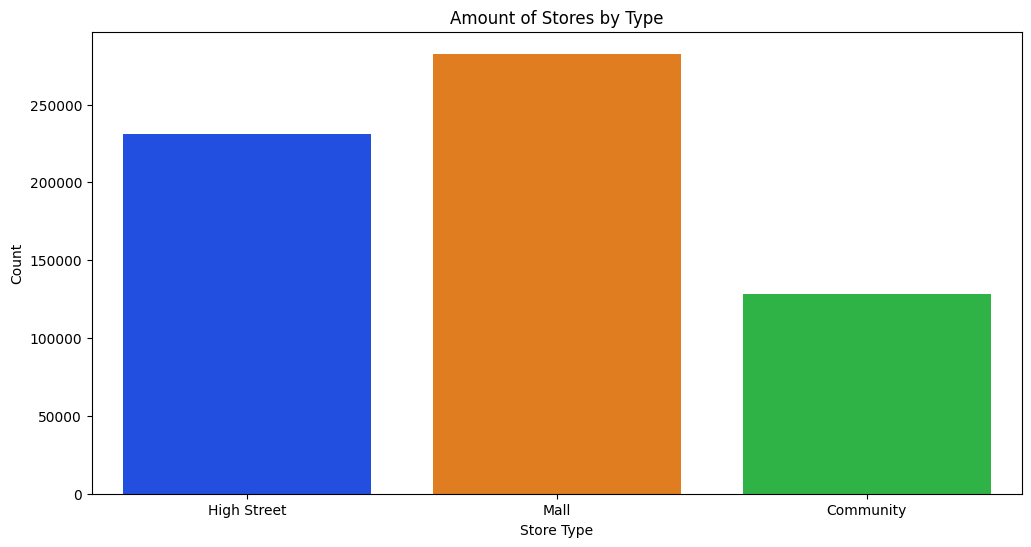

In [16]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='store_type', hue='store_type', palette='bright')
plt.title('Amount of Stores by Type')
plt.xlabel('Store Type')
plt.ylabel('Count')
plt.show()


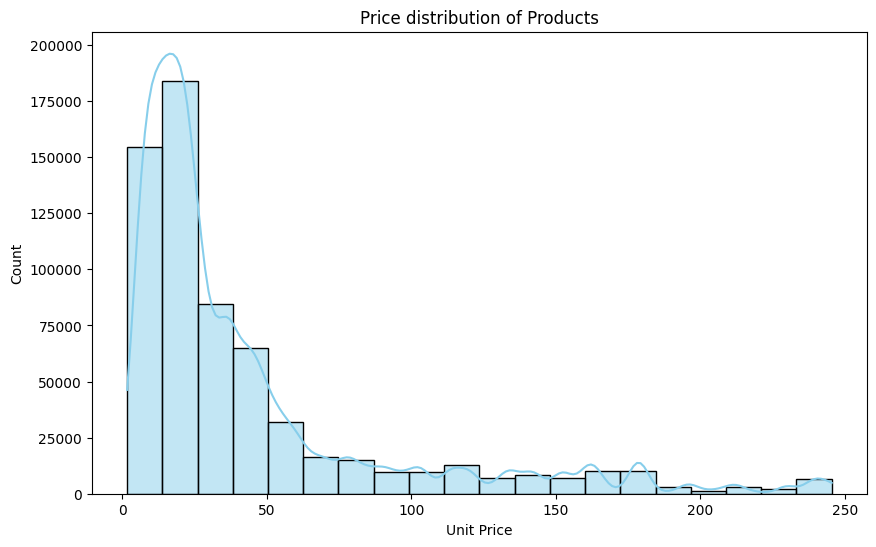

In [20]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='unit_price_x', bins=20, kde=True, color='skyblue')
plt.title('Price distribution of Products')
plt.xlabel('Unit Price')
plt.ylabel('Count')
plt.show()

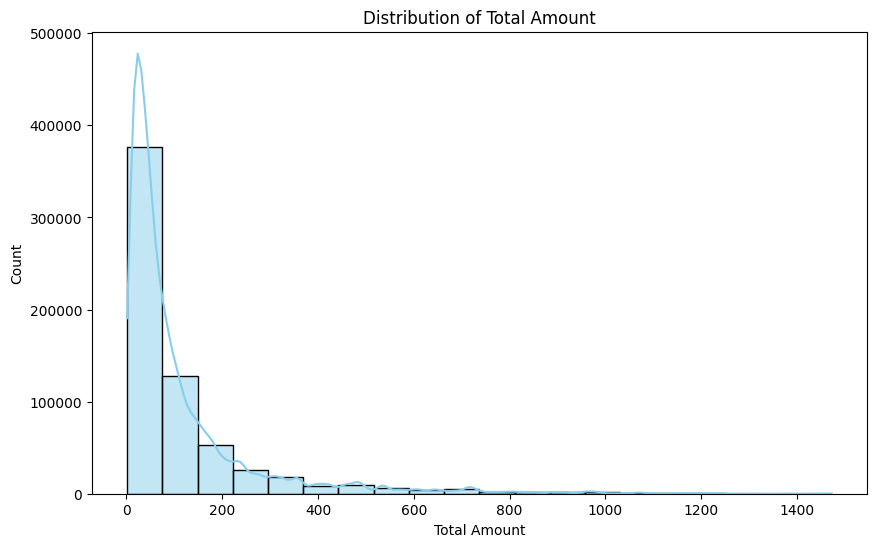

In [22]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='total_value', bins=20, kde=True, color='skyblue')
plt.title('Distribution of Total Amount')
plt.xlabel('Total Amount')
plt.ylabel('Count')
plt.show()

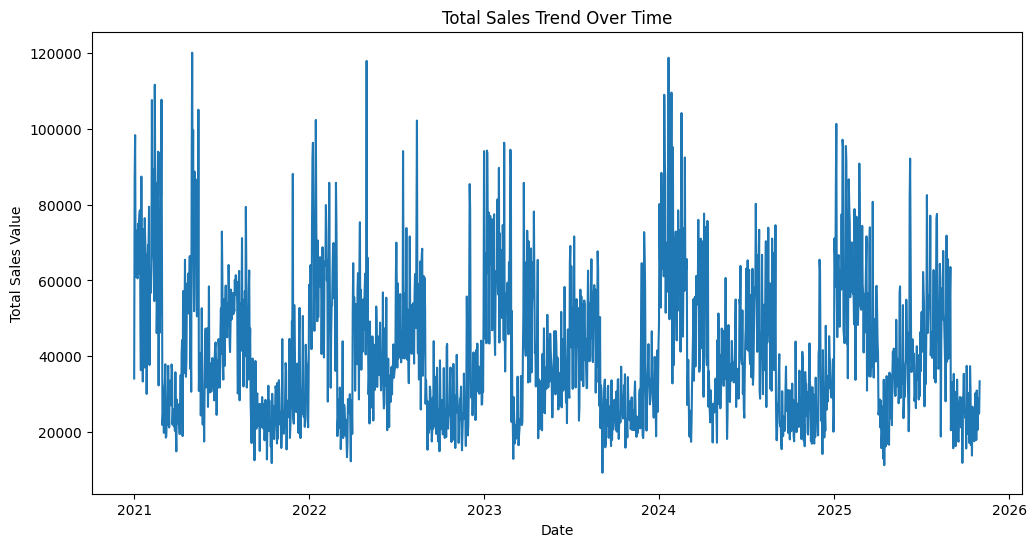

In [24]:

df['date'] = pd.to_datetime(df['date'])


df['Year'] = df['date'].dt.year
df['Month'] = df['date'].dt.month

# Plot trends over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='total_value', estimator='sum', ci=None)
plt.title('Total Sales Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales Value')
plt.show()

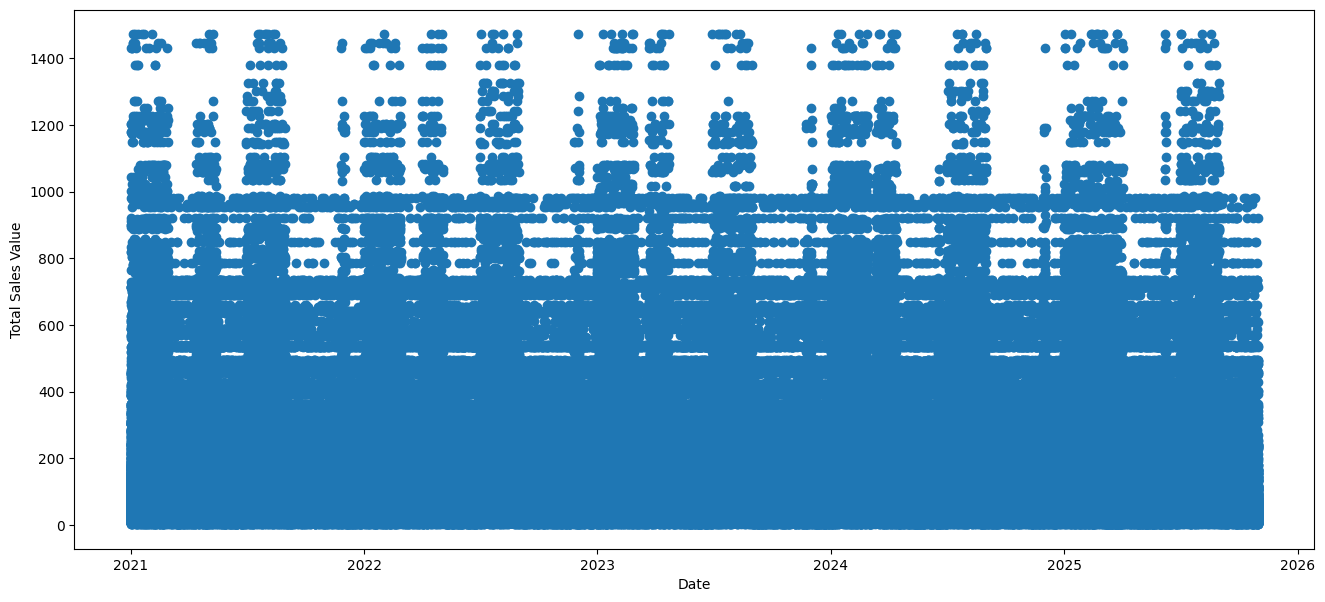

In [26]:
plt.figure(figsize=(16,7))
plt.scatter(x=df['date'], y=df['total_value'])
plt.xlabel('Date')
plt.ylabel('Total Sales Value')
plt.show()

In [27]:
df.dropna()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,store_name,...,store_type,opening_date,sku_name,category,subcategory,unit_price_y,cost_price,brand,Year,Month
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,BlueMart Store 26,...,High Street,2017-06-01 08:11:42.439024392,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,2021,1
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,BlueMart Store 03,...,Community,2017-07-31 00:00:00.000000000,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,2021,1
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,BlueMart Store 02,...,High Street,2017-07-01 00:00:00.000000000,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,2021,1
5,2021-01-01,25,1067,1286.0,1,42.13,42.13,MobileApp,15.0,BlueMart Store 25,...,High Street,2017-05-23 10:32:11.707317074,Grocery_Cereals_1067,Grocery,Cereals,49.57,32.38,Premium,2021,1
7,2021-01-01,38,1008,3160.0,2,37.35,74.70,Store,15.0,BlueMart Store 38,...,High Street,2017-09-16 04:05:51.219512196,Personal Care_Shampoo_1008,Personal Care,Shampoo,43.94,31.77,Premium,2021,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641838,2025-10-31,29,1102,2525.0,3,21.54,64.62,Website,0.0,BlueMart Store 29,...,Mall,2017-06-28 01:10:14.634146342,Snacks_Biscuits_1102,Snacks,Biscuits,21.54,13.18,Premium,2025,10
641839,2025-10-31,13,1029,3091.0,2,27.90,55.80,Amazon.ae,0.0,BlueMart Store 13,...,Community,2017-05-01 00:00:00.000000000,Grocery_Canned Goods_1029,Grocery,Canned Goods,27.90,19.78,Premium,2025,10
641840,2025-10-31,8,1180,2345.0,1,8.40,8.40,Store,0.0,BlueMart Store 08,...,Mall,2017-12-28 00:00:00.000000000,Grocery_Spices_1180,Grocery,Spices,8.40,6.20,Premium,2025,10
641841,2025-10-31,27,1158,1945.0,3,7.27,21.81,Store,0.0,BlueMart Store 27,...,High Street,2017-06-10 05:51:13.170731708,Snacks_Crackers_1158,Snacks,Crackers,7.27,5.31,Local,2025,10


## Univariate Analysis
**before removing outliers**

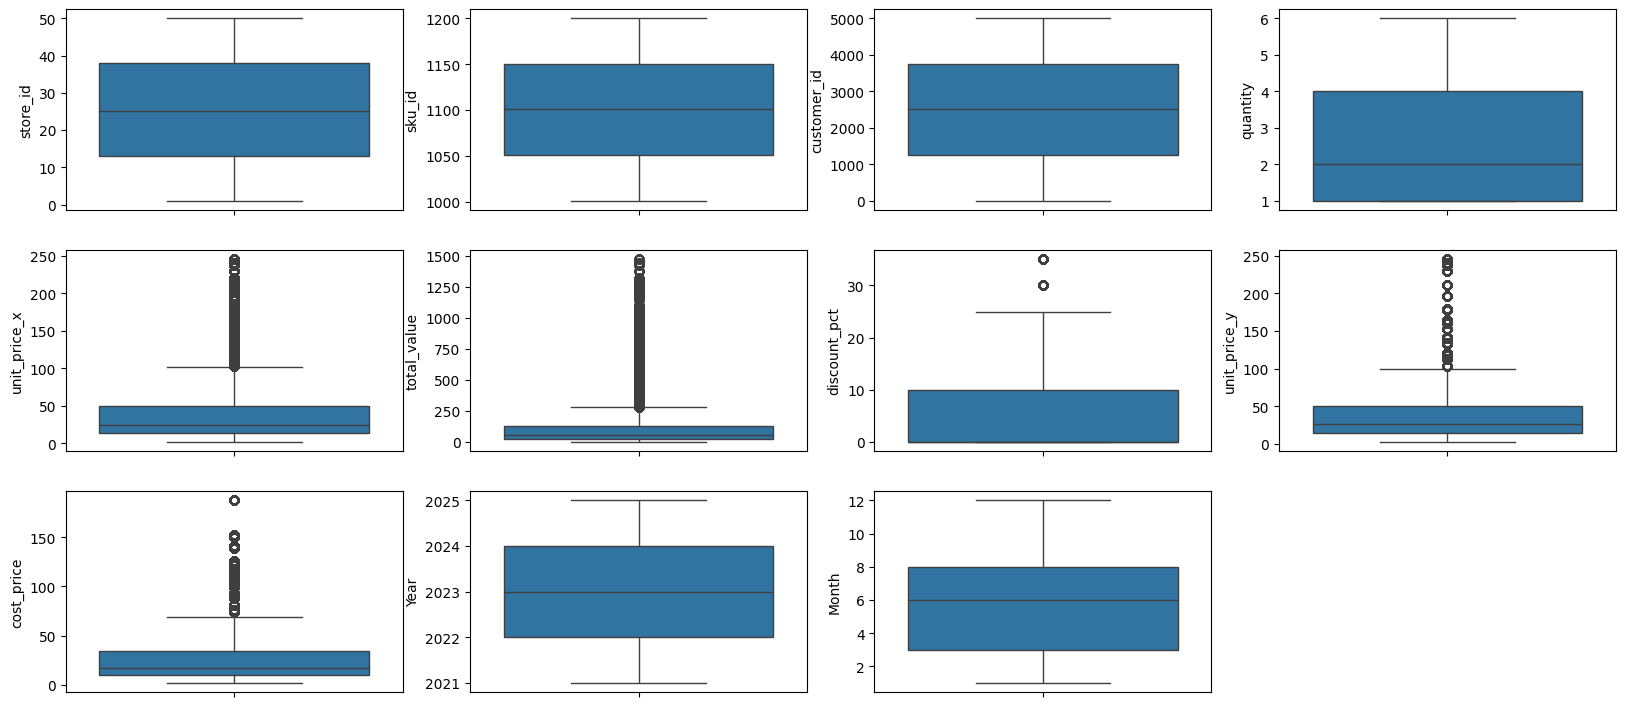

In [28]:
plt.figure(figsize=(20, 12))
for i, column in enumerate(df.select_dtypes(include='number'),1):
    plt.subplot(4,4,i)
    sns.boxplot(df[column])

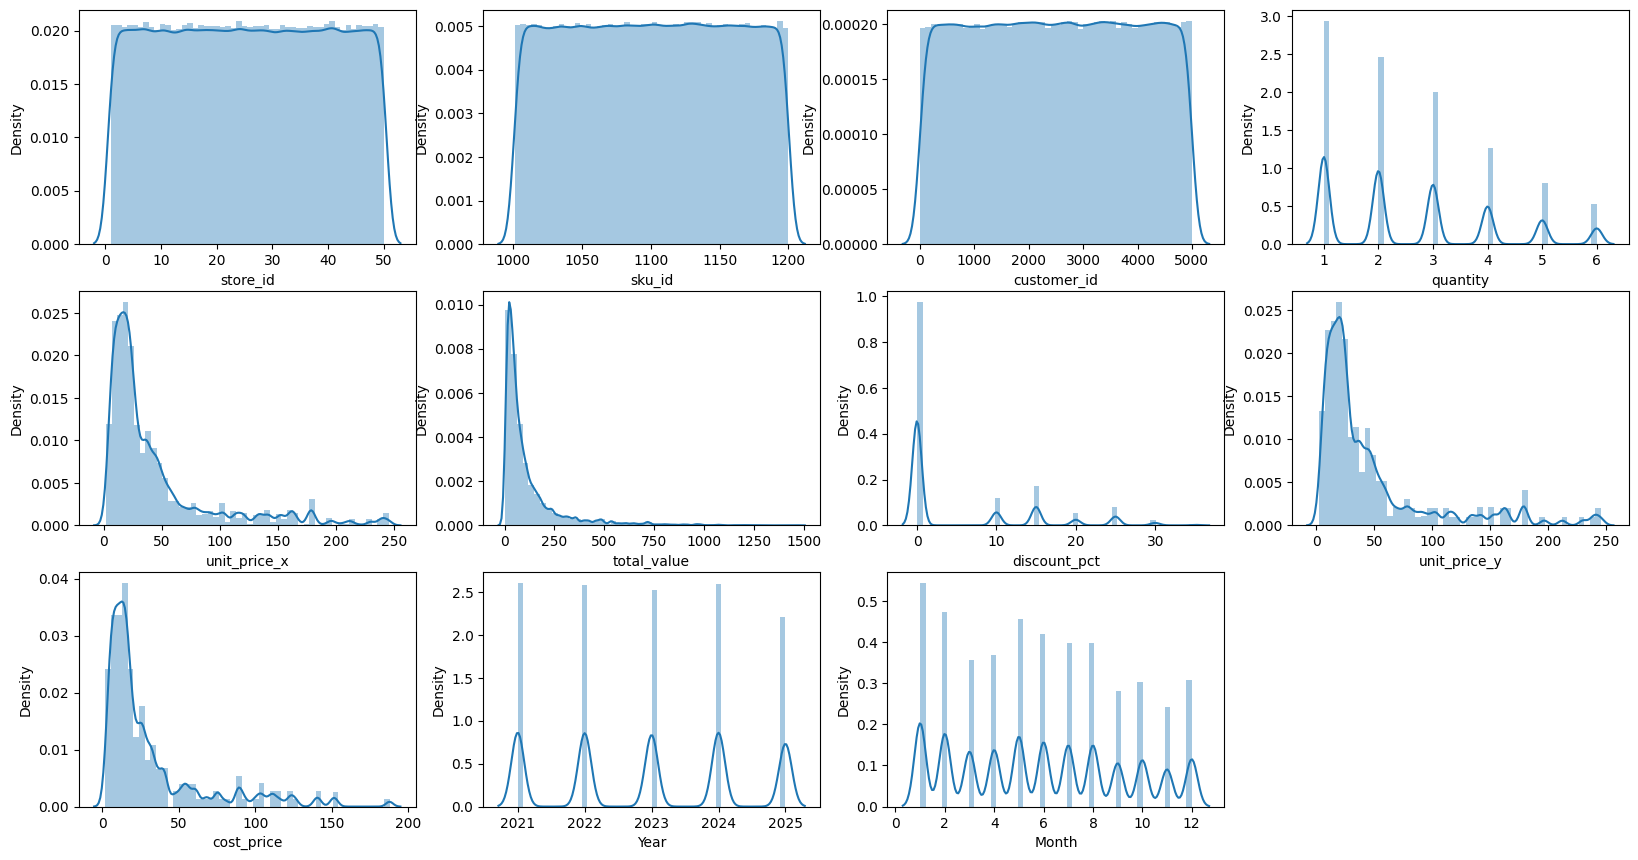

In [29]:
plt.figure(figsize=(20, 14))
for i, column in enumerate(df.select_dtypes(include='number'),1):
    plt.subplot(4,4,i)
    sns.distplot(df[column])

In [30]:
for i in df.select_dtypes(include='number'):
    skewness=df[i].skew()
    print("The skewness of",i,"is",skewness)

The skewness of store_id is 0.0007495590804904221
The skewness of sku_id is -0.002727973413124181
The skewness of customer_id is -0.0027468656559125606
The skewness of quantity is 0.6802919487803953
The skewness of unit_price_x is 2.094361000091265
The skewness of total_value is 3.200066613005961
The skewness of discount_pct is 1.3406696967290344
The skewness of unit_price_y is 2.0493308275137183
The skewness of cost_price is 2.052853509486284
The skewness of Year is 0.040847883248612514
The skewness of Month is 0.19932380019163792


# Checking for outliers

In [31]:
df.shape

(641843, 21)

In [32]:
df.dtypes

,0
date,datetime64[ns]
store_id,int64
sku_id,int64
customer_id,float64
quantity,int64
unit_price_x,float64
total_value,float64
channel,object
discount_pct,float64
store_name,object


In [33]:
df.duplicated().sum()

np.int64(45)

In [34]:
df.describe(include='object')

,channel,store_name,city,store_type,opening_date,sku_name,category,subcategory,brand
count,641843,641843,641843,641843,641843,641843,641843,641843,641843
unique,5,50,3,3,50,200,7,33,5
top,Store,BlueMart Store 41,Dubai,Mall,2017-10-12 21:04:23.414634148,Dairy_Butter_1194,Electronics,Batteries,Premium
freq,274802,13144,360142,282641,13144,3387,137640,41585,182672


In [35]:
df.describe()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,discount_pct,unit_price_y,cost_price,Year,Month
count,641843,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,2023-05-20 21:46:27.468586496,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316,46.634125,31.032444,2022.938064,5.875521
min,2021-01-01 00:00:00,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000,2.610000,1.680000,2021.000000,1.000000
25%,2022-02-25 00:00:00,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000,15.160000,10.070000,2022.000000,3.000000
50%,2023-05-19 00:00:00,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000,25.910000,17.120000,2023.000000,6.000000
75%,2024-07-31 00:00:00,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000,50.490000,34.180000,2024.000000,8.000000
max,2025-10-31 00:00:00,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000,245.380000,187.670000,2025.000000,12.000000
std,NaN,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765,51.387097,34.300009,1.395810,3.405351


In [37]:
df.isnull().sum()

,0
date,0
store_id,0
sku_id,0
customer_id,159821
quantity,0
unit_price_x,0
total_value,0
channel,0
discount_pct,0
store_name,0


In [38]:
df['MarkDown1'].dropna()

KeyError: 'MarkDown1'

In [43]:
# Permanently drop rows with missing values (NaN) from the dataset
print(f"Dataset shape before dropping NaNs: {df.shape}")

# Using inplace=True to apply changes directly to df
df.dropna(inplace=True)

print(f"Dataset shape after dropping NaNs: {df.shape}")
print("\nRemaining missing values per column:")
print(df.isnull().sum())

Dataset shape before dropping NaNs: (482022, 21)
Dataset shape after dropping NaNs: (482022, 21)

Remaining missing values per column:
date            0
store_id        0
sku_id          0
customer_id     0
quantity        0
unit_price_x    0
total_value     0
channel         0
discount_pct    0
store_name      0
city            0
store_type      0
opening_date    0
sku_name        0
category        0
subcategory     0
unit_price_y    0
cost_price      0
brand           0
Year            0
Month           0
dtype: int64


In [44]:
# Removing unnecessary duplicate or less important columns for cleaner analysis
columns_to_drop = ['unit_price_y', 'opening_date']

# Drop columns only if they exist in the dataframe
df_cleaned = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

print("Remaining columns after cleaning unnecessary columns:")
print(df_cleaned.columns.tolist())

# Display first few rows
display(df_cleaned.head())

Remaining columns after cleaning unnecessary columns:
['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price_x', 'total_value', 'channel', 'discount_pct', 'store_name', 'city', 'store_type', 'sku_name', 'category', 'subcategory', 'cost_price', 'brand', 'Year', 'Month']


,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,store_name,city,store_type,sku_name,category,subcategory,cost_price,brand,Year,Month
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,BlueMart Store 26,Abu Dhabi,High Street,Dairy_Cheese_1124,Dairy,Cheese,13.62,Premium,2021,1
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,BlueMart Store 03,Abu Dhabi,Community,Electronics_Cables_1164,Electronics,Cables,126.30,BlueMart,2021,1
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,BlueMart Store 02,Sharjah,High Street,Snacks_Chips_1093,Snacks,Chips,5.29,BlueMart,2021,1
5,2021-01-01,25,1067,1286.0,1,42.13,42.13,MobileApp,15.0,BlueMart Store 25,Dubai,High Street,Grocery_Cereals_1067,Grocery,Cereals,32.38,Premium,2021,1
7,2021-01-01,38,1008,3160.0,2,37.35,74.70,Store,15.0,BlueMart Store 38,Dubai,High Street,Personal Care_Shampoo_1008,Personal Care,Shampoo,31.77,Premium,2021,1


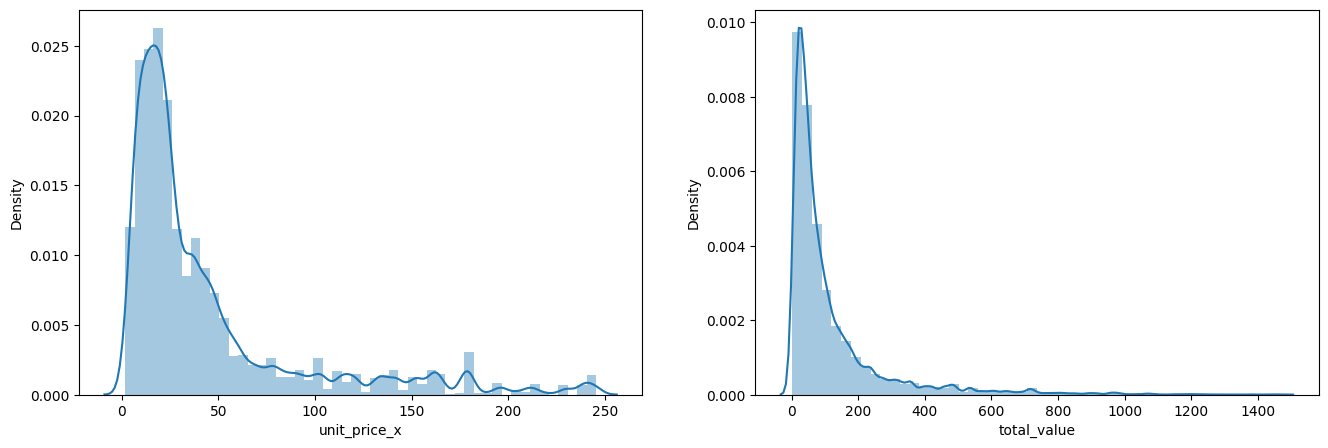

In [46]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['unit_price_x'])

plt.subplot(1,2,2)
sns.distplot(df['total_value'])

plt.show()

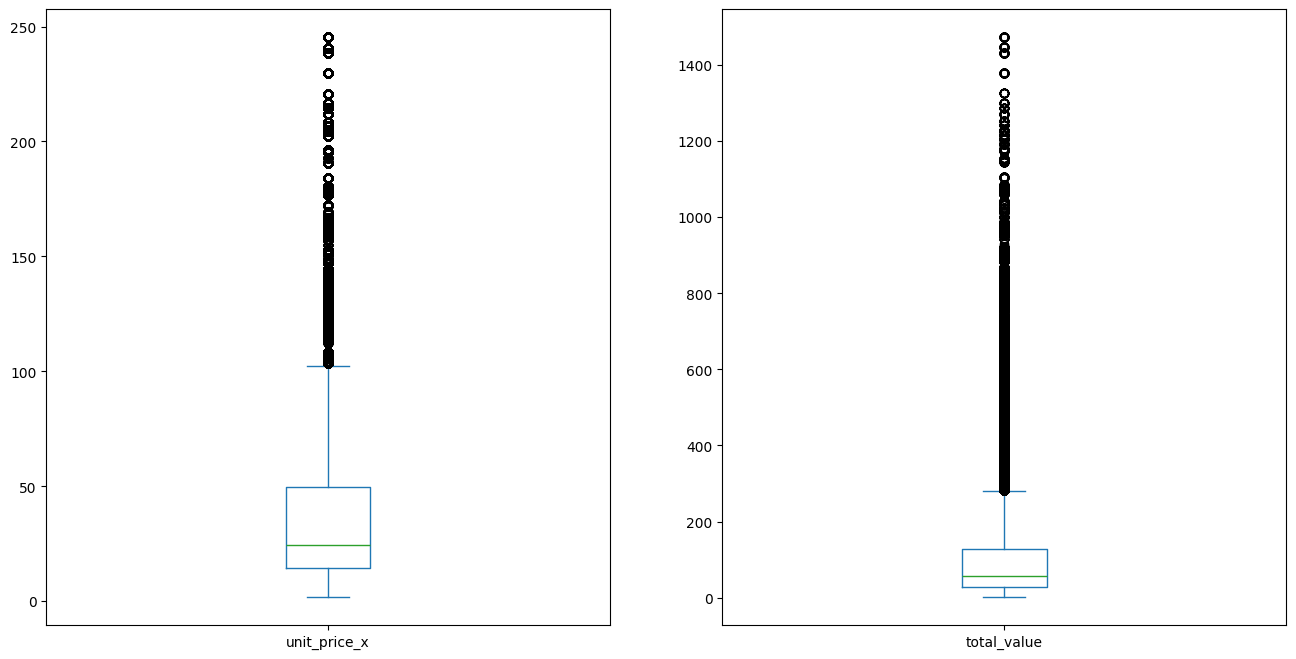

In [47]:
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
df['unit_price_x'].plot(kind='box')

plt.subplot(1,2,2)
df['total_value'].plot(kind='box')
plt.show()

In [48]:
df=df.drop('unit_price_x',axis=1)
df

,date,store_id,sku_id,customer_id,quantity,total_value,channel,discount_pct,store_name,city,store_type,opening_date,sku_name,category,subcategory,unit_price_y,cost_price,brand,Year,Month
0,2021-01-01,26,1124,2961.0,1,20.08,Store,15.0,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,2021,1
3,2021-01-01,3,1164,3694.0,6,1177.44,Website,0.0,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,2021,1
4,2021-01-01,2,1093,1252.0,1,7.98,Store,0.0,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,2021,1
5,2021-01-01,25,1067,1286.0,1,42.13,MobileApp,15.0,BlueMart Store 25,Dubai,High Street,2017-05-23 10:32:11.707317074,Grocery_Cereals_1067,Grocery,Cereals,49.57,32.38,Premium,2021,1
7,2021-01-01,38,1008,3160.0,2,74.70,Store,15.0,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,Personal Care_Shampoo_1008,Personal Care,Shampoo,43.94,31.77,Premium,2021,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641838,2025-10-31,29,1102,2525.0,3,64.62,Website,0.0,BlueMart Store 29,Abu Dhabi,Mall,2017-06-28 01:10:14.634146342,Snacks_Biscuits_1102,Snacks,Biscuits,21.54,13.18,Premium,2025,10
641839,2025-10-31,13,1029,3091.0,2,55.80,Amazon.ae,0.0,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000,Grocery_Canned Goods_1029,Grocery,Canned Goods,27.90,19.78,Premium,2025,10
641840,2025-10-31,8,1180,2345.0,1,8.40,Store,0.0,BlueMart Store 08,Sharjah,Mall,2017-12-28 00:00:00.000000000,Grocery_Spices_1180,Grocery,Spices,8.40,6.20,Premium,2025,10
641841,2025-10-31,27,1158,1945.0,3,21.81,Store,0.0,BlueMart Store 27,Dubai,High Street,2017-06-10 05:51:13.170731708,Snacks_Crackers_1158,Snacks,Crackers,7.27,5.31,Local,2025,10


In [49]:
df=df.drop('unit_price_y',axis=1)
df

,date,store_id,sku_id,customer_id,quantity,total_value,channel,discount_pct,store_name,city,store_type,opening_date,sku_name,category,subcategory,cost_price,brand,Year,Month
0,2021-01-01,26,1124,2961.0,1,20.08,Store,15.0,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,Dairy_Cheese_1124,Dairy,Cheese,13.62,Premium,2021,1
3,2021-01-01,3,1164,3694.0,6,1177.44,Website,0.0,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,Electronics_Cables_1164,Electronics,Cables,126.30,BlueMart,2021,1
4,2021-01-01,2,1093,1252.0,1,7.98,Store,0.0,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,Snacks_Chips_1093,Snacks,Chips,5.29,BlueMart,2021,1
5,2021-01-01,25,1067,1286.0,1,42.13,MobileApp,15.0,BlueMart Store 25,Dubai,High Street,2017-05-23 10:32:11.707317074,Grocery_Cereals_1067,Grocery,Cereals,32.38,Premium,2021,1
7,2021-01-01,38,1008,3160.0,2,74.70,Store,15.0,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,Personal Care_Shampoo_1008,Personal Care,Shampoo,31.77,Premium,2021,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641838,2025-10-31,29,1102,2525.0,3,64.62,Website,0.0,BlueMart Store 29,Abu Dhabi,Mall,2017-06-28 01:10:14.634146342,Snacks_Biscuits_1102,Snacks,Biscuits,13.18,Premium,2025,10
641839,2025-10-31,13,1029,3091.0,2,55.80,Amazon.ae,0.0,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000,Grocery_Canned Goods_1029,Grocery,Canned Goods,19.78,Premium,2025,10
641840,2025-10-31,8,1180,2345.0,1,8.40,Store,0.0,BlueMart Store 08,Sharjah,Mall,2017-12-28 00:00:00.000000000,Grocery_Spices_1180,Grocery,Spices,6.20,Premium,2025,10
641841,2025-10-31,27,1158,1945.0,3,21.81,Store,0.0,BlueMart Store 27,Dubai,High Street,2017-06-10 05:51:13.170731708,Snacks_Crackers_1158,Snacks,Crackers,5.31,Local,2025,10


In [51]:
df.corr(numeric_only=True)

,store_id,sku_id,customer_id,quantity,total_value,discount_pct,cost_price,Year,Month
store_id,1.000000,-0.001423,-0.000454,-0.001325,0.000181,0.000717,0.000175,-0.001388,-0.000520
sku_id,-0.001423,1.000000,0.001187,-0.000164,0.008027,-0.002070,0.015704,-0.000105,0.002613
customer_id,-0.000454,0.001187,1.000000,0.001453,-0.000900,0.000392,-0.000279,-0.001817,-0.000558
quantity,-0.001325,-0.000164,0.001453,1.000000,0.394083,0.225858,0.001857,0.008889,-0.191464
total_value,0.000181,0.008027,-0.000900,0.394083,1.000000,0.016100,0.794344,0.002782,-0.057885
discount_pct,0.000717,-0.002070,0.000392,0.225858,0.016100,1.000000,-0.000683,-0.006794,-0.336397
cost_price,0.000175,0.015704,-0.000279,0.001857,0.794344,-0.000683,1.000000,-0.002523,-0.001003
Year,-0.001388,-0.000105,-0.001817,0.008889,0.002782,-0.006794,-0.002523,1.000000,-0.075368
Month,-0.000520,0.002613,-0.000558,-0.191464,-0.057885,-0.336397,-0.001003,-0.075368,1.000000


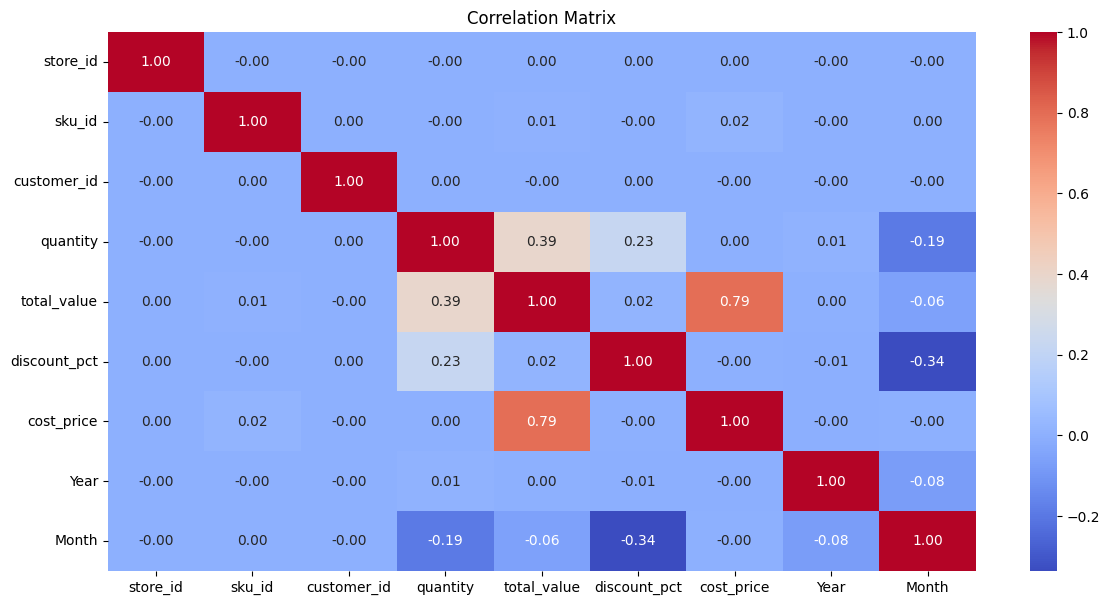

In [53]:
plt.figure(figsize=(14, 7))
# Use numeric_only=True to prevent ValueError with categorical text columns
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

# Treatment Of Outliers..

In [55]:
# Calculate the first quartile (25th percentile) for numeric columns only
q1 = df.quantile(0.25, numeric_only=True)
q1

,0.25
store_id,13.00
sku_id,1051.00
customer_id,1260.00
quantity,1.00
total_value,27.32
discount_pct,0.00
cost_price,10.07
Year,2022.00
Month,3.00


In [56]:
# Calculate the third quartile (75th percentile) for numeric columns only
q3 = df.quantile(0.75, numeric_only=True)
q3

,0.75
store_id,38.00
sku_id,1150.00
customer_id,3752.00
quantity,4.00
total_value,129.00
discount_pct,10.00
cost_price,34.18
Year,2024.00
Month,8.00


In [57]:
Iqr=q3-q1
Iqr

,0
store_id,25.00
sku_id,99.00
customer_id,2492.00
quantity,3.00
total_value,101.68
discount_pct,10.00
cost_price,24.11
Year,2.00
Month,5.00


In [59]:
# Calculate upper bound for outliers using an existing column like 'total_value'
high_outliers = q3['total_value'] + 1.5 * Iqr['total_value']
high_outliers

np.float64(281.52)

In [62]:
# Calculate lower bound for outliers using an existing column like 'total_value'
low_outliers = q1['total_value'] - 1.5 * Iqr['total_value']
low_outliers

np.float64(-125.20000000000002)

---
## Capping
---

In [65]:
import numpy as np
new_df = df.copy()

# Perform capping on 'total_value' using the previously calculated high and low outlier boundaries
new_df['total_value'] = np.where(
    new_df['total_value'] > high_outliers,
    high_outliers,
    np.where(
        new_df['total_value'] < low_outliers,
        low_outliers,
        new_df['total_value']
    )
)

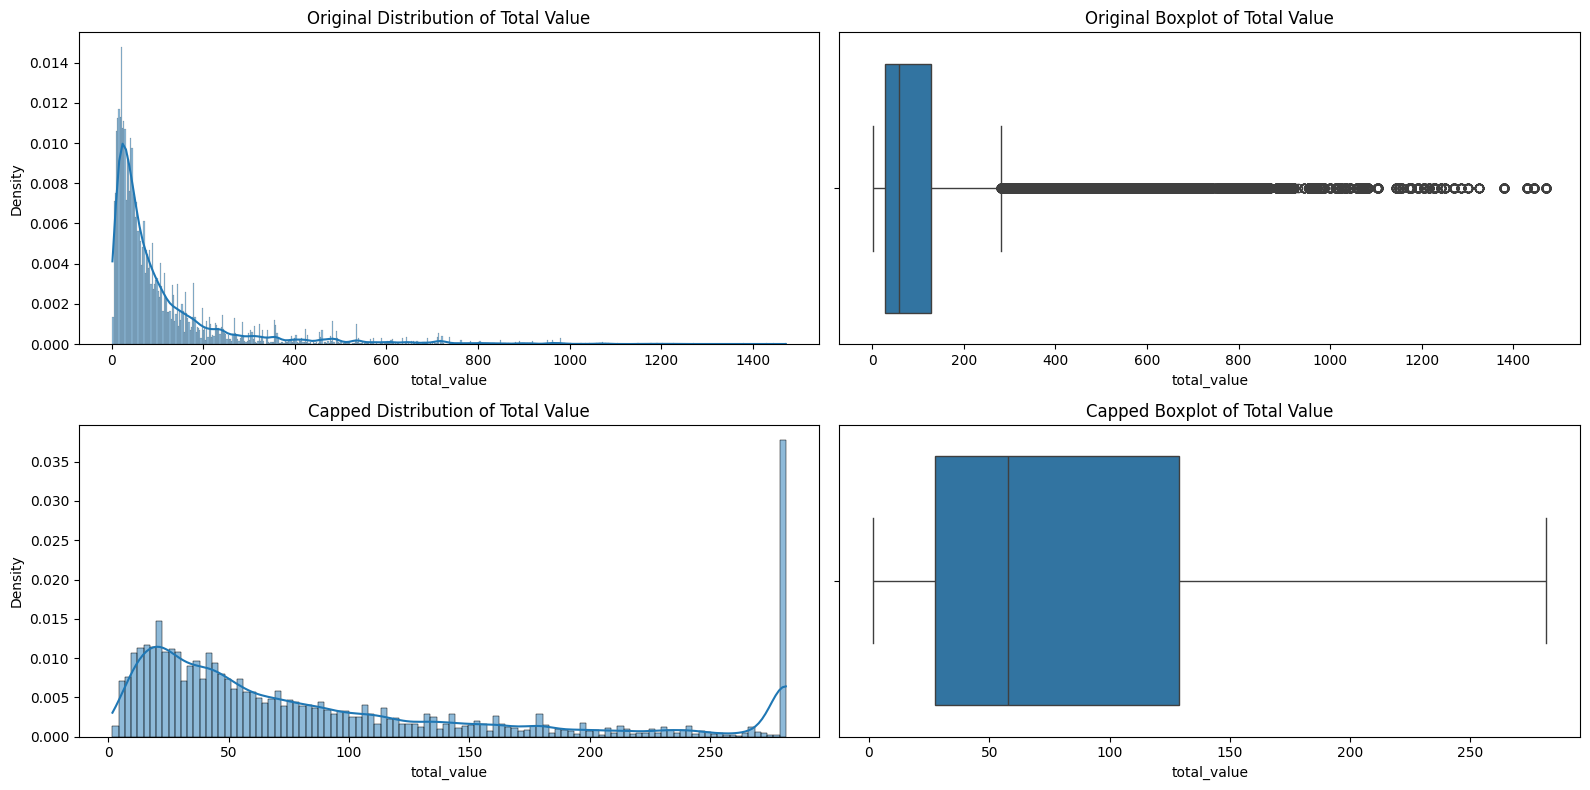

In [66]:
plt.figure(figsize=(16,8))

# Before Capping: Distribution of total_value
plt.subplot(2,2,1)
sns.histplot(df['total_value'], kde=True, stat="density")
plt.title('Original Distribution of Total Value')

# Before Capping: Boxplot of total_value
plt.subplot(2,2,2)
sns.boxplot(x=df['total_value'])
plt.title('Original Boxplot of Total Value')

# After Capping: Distribution of capped total_value
plt.subplot(2,2,3)
sns.histplot(new_df['total_value'], kde=True, stat="density")
plt.title('Capped Distribution of Total Value')

# After Capping: Boxplot of capped total_value
plt.subplot(2,2,4)
sns.boxplot(x=new_df['total_value'])
plt.title('Capped Boxplot of Total Value')

plt.tight_layout()
plt.show()

In [68]:
# Calculate outlier thresholds for 'cost_price'
high_outliers_cost = q3['cost_price'] + 1.5 * Iqr['cost_price']
low_outliers_cost = q1['cost_price'] - 1.5 * Iqr['cost_price']

# Cap outliers in the 'cost_price' column
new_df['cost_price'] = np.where(
    new_df['cost_price'] > high_outliers_cost,
    high_outliers_cost,
    np.where(
        new_df['cost_price'] < low_outliers_cost,
        low_outliers_cost,
        new_df['cost_price']
    )
)

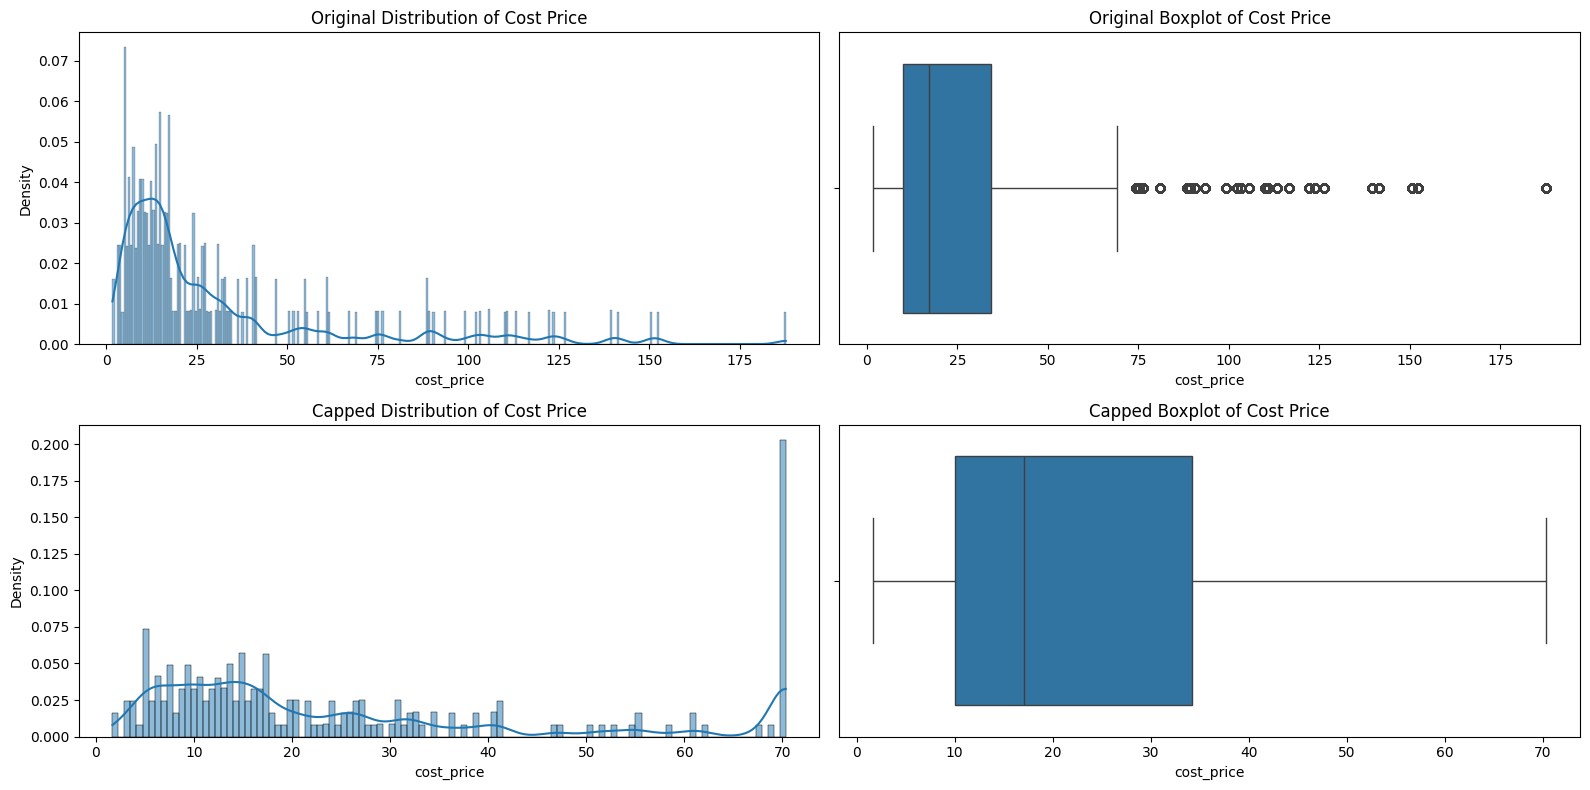

In [69]:
plt.figure(figsize=(16,8))

# Before Capping: Distribution of cost_price
plt.subplot(2,2,1)
sns.histplot(df['cost_price'], kde=True, stat="density")
plt.title('Original Distribution of Cost Price')

# Before Capping: Boxplot of cost_price
plt.subplot(2,2,2)
sns.boxplot(x=df['cost_price'])
plt.title('Original Boxplot of Cost Price')

# After Capping: Distribution of capped cost_price
plt.subplot(2,2,3)
sns.histplot(new_df['cost_price'], kde=True, stat="density")
plt.title('Capped Distribution of Cost Price')

# After Capping: Boxplot of capped cost_price
plt.subplot(2,2,4)
sns.boxplot(x=new_df['cost_price'])
plt.title('Capped Boxplot of Cost Price')

plt.tight_layout()
plt.show()

***
# Removing Outliers
***

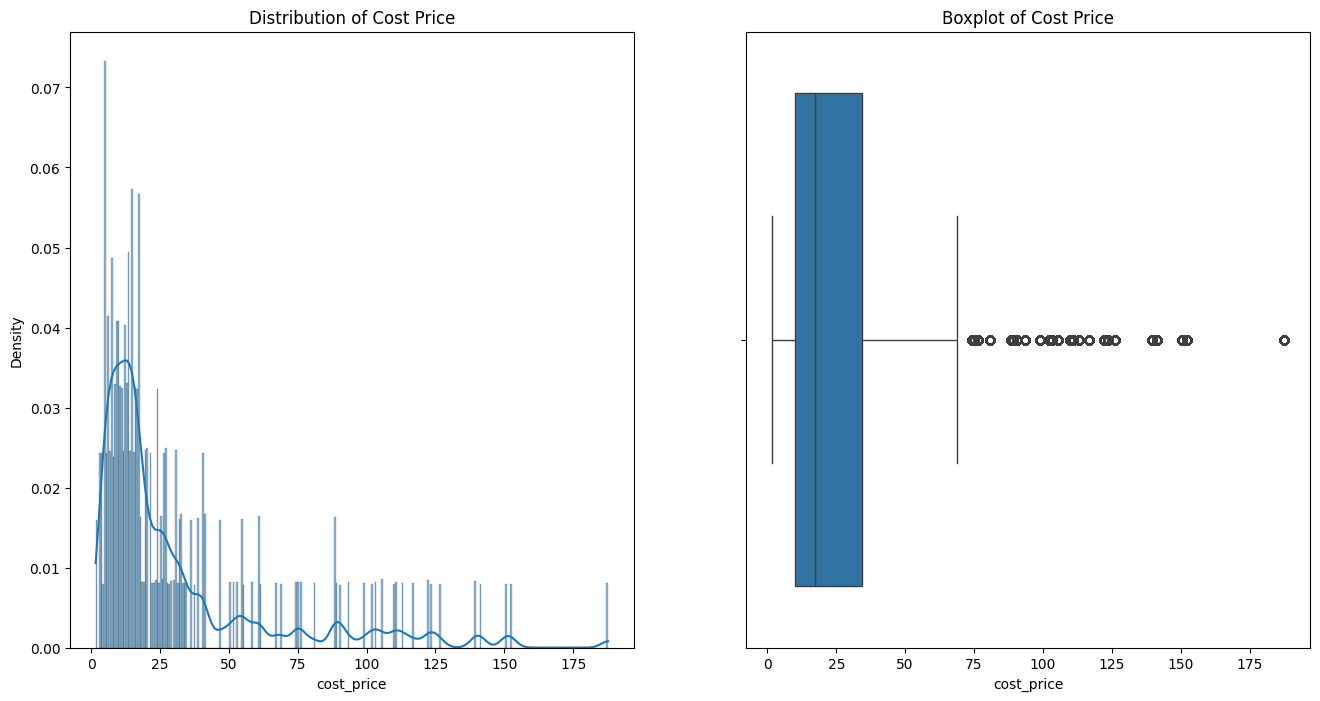

In [70]:
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
sns.histplot(df['cost_price'], kde=True, stat='density')
plt.title('Distribution of Cost Price')

plt.subplot(1,2,2)
sns.boxplot(x=df['cost_price'])
plt.title('Boxplot of Cost Price')
plt.show()

In [72]:
high_out_cost = q3['cost_price'] + 1.5 * Iqr['cost_price']
high_out_cost

np.float64(70.345)

In [73]:
low_out_cost = q1['cost_price'] - 1.5 * Iqr['cost_price']
low_out_cost

np.float64(-26.095)

In [79]:
index_ = np.where(df['cost_price'] > high_out_cost)
index_

(array([     1,      6,     15, ..., 481967, 481973, 481977],
       shape=(59988,)),)

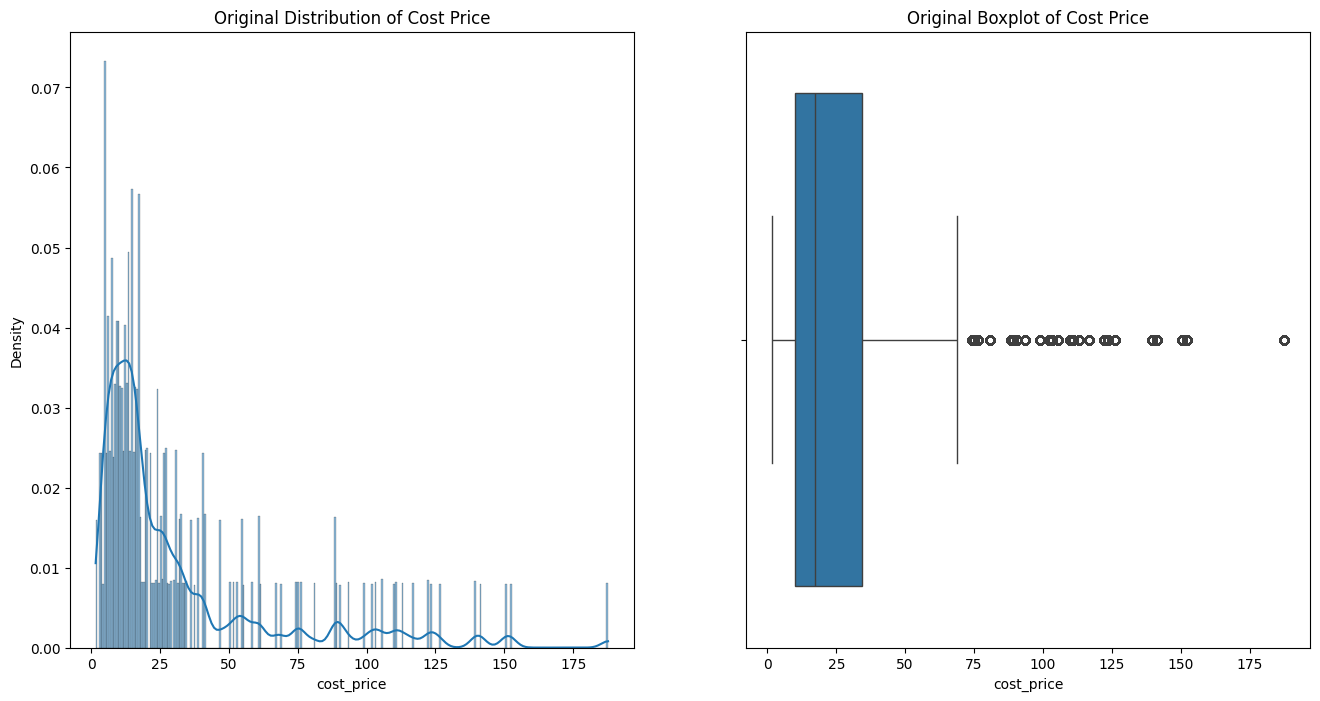

In [80]:
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
sns.histplot(df['cost_price'], kde=True, stat='density')
plt.title('Original Distribution of Cost Price')

plt.subplot(1,2,2)
sns.boxplot(x=df['cost_price'])
plt.title('Original Boxplot of Cost Price')
plt.show()

---
### do it again by capping
---

In [81]:
new_df['cost_price'] = np.where(new_df['cost_price'] > high_out_cost,
                                high_out_cost,
                                np.where(new_df['cost_price'] < low_out_cost,
                                low_out_cost,
                                new_df['cost_price'])
)
new_df['cost_price'].describe()

,cost_price
count,482022.000000
mean,26.006357
std,21.550313
min,1.680000
25%,10.070000
50%,17.110000
75%,34.180000
max,70.345000


In [83]:
high_out_qty = q3['quantity'] + 1.5 * Iqr['quantity']
high_out_qty

np.float64(8.5)

In [84]:
low_out_qty = q1['quantity'] - 1.5 * Iqr['quantity']
low_out_qty

np.float64(-3.5)

In [85]:
new_df['quantity'] = np.where(new_df['quantity'] > high_out_qty,
                              high_out_qty,
                              np.where(new_df['quantity'] < low_out_qty,
                              low_out_qty,
                              new_df['quantity'])
)
new_df['quantity'].describe()

,quantity
count,482022.000000
mean,2.612949
std,1.480790
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,6.000000


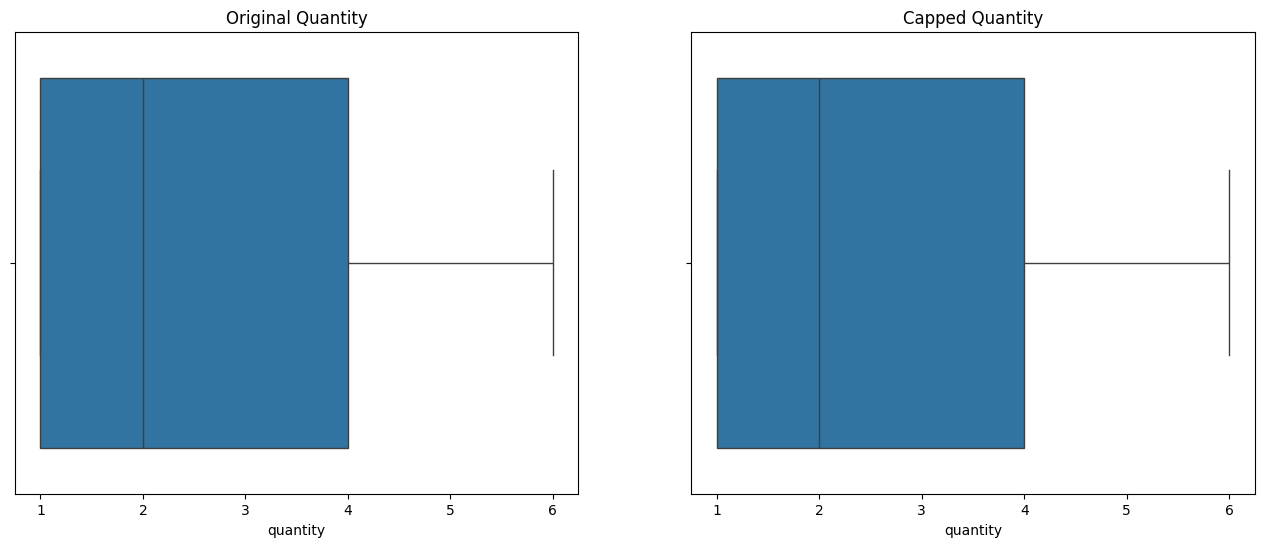

In [86]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['quantity'])
plt.title('Original Quantity')

plt.subplot(1, 2, 2)
sns.boxplot(x=new_df['quantity'])
plt.title('Capped Quantity')
plt.show()

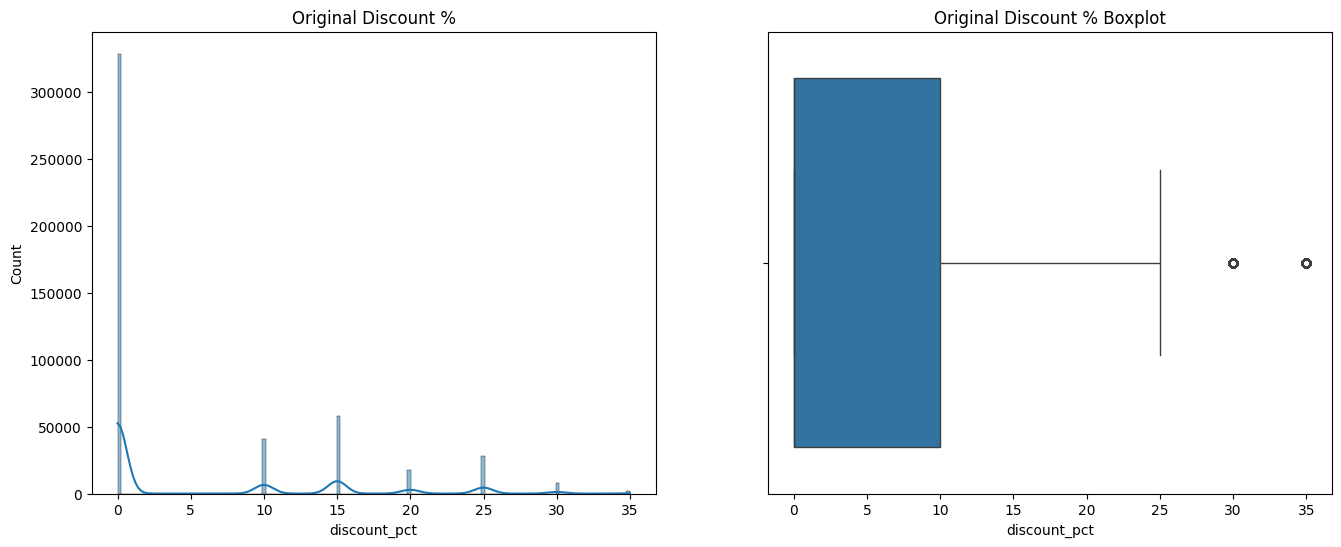

In [87]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.histplot(df['discount_pct'], kde=True)
plt.title('Original Discount %')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['discount_pct'])
plt.title('Original Discount % Boxplot')
plt.show()

In [88]:
high_out_disc = q3['discount_pct'] + 1.5 * Iqr['discount_pct']
high_out_disc

np.float64(25.0)

In [89]:
low_out_disc = q1['discount_pct'] - 1.5 * Iqr['discount_pct']
low_out_disc

np.float64(-15.0)

In [90]:
new_df['discount_pct'] = np.where(new_df['discount_pct'] > high_out_disc,
                                  high_out_disc,
                                  np.where(new_df['discount_pct'] < low_out_disc,
                                  low_out_disc,
                                  new_df['discount_pct'])
)
new_df['discount_pct'].describe()

,discount_pct
count,482022.000000
mean,5.311314
std,8.376186
min,0.000000
25%,0.000000
50%,0.000000
75%,10.000000
max,25.000000


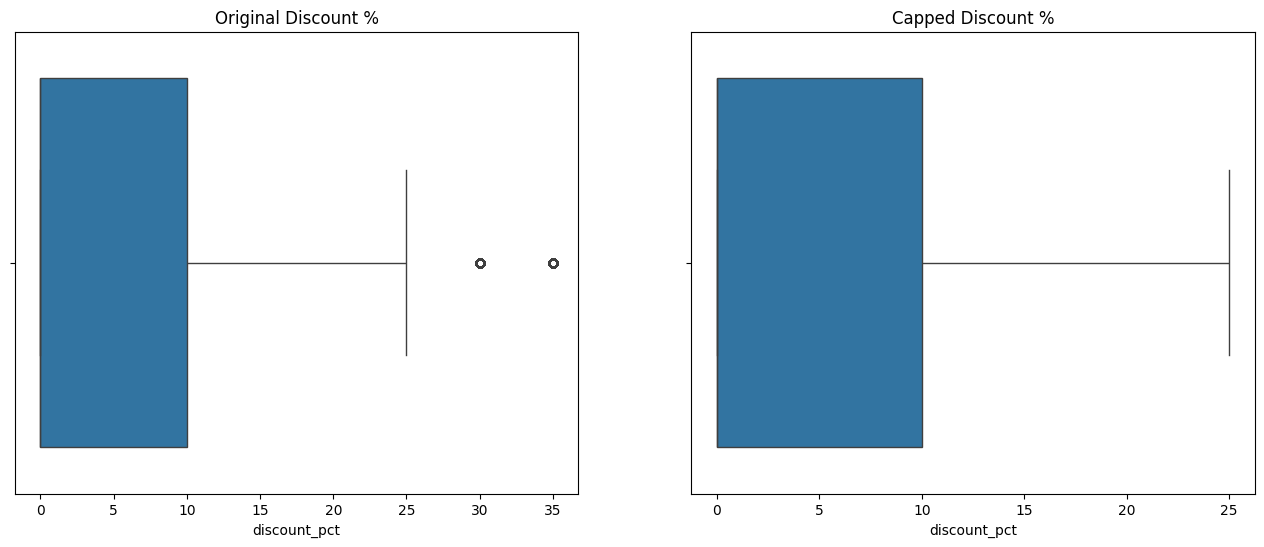

In [91]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['discount_pct'])
plt.title('Original Discount %')

plt.subplot(1, 2, 2)
sns.boxplot(x=new_df['discount_pct'])
plt.title('Capped Discount %')
plt.show()

In [93]:
high_out_cust = q3['customer_id'] + 1.5 * Iqr['customer_id']
high_out_cust

np.float64(7490.0)

In [94]:
low_out_cust = q1['customer_id'] - 1.5 * Iqr['customer_id']
low_out_cust

np.float64(-2478.0)

In [95]:
new_df['customer_id'] = np.where(new_df['customer_id'] > high_out_cust,
                                 high_out_cust,
                                 np.where(new_df['customer_id'] < low_out_cust,
                                 low_out_cust,
                                 new_df['customer_id'])
)
new_df['customer_id'].describe()

,customer_id
count,482022.000000
mean,2504.986828
std,1442.340254
min,1.000000
25%,1260.000000
50%,2507.000000
75%,3752.000000
max,5000.000000


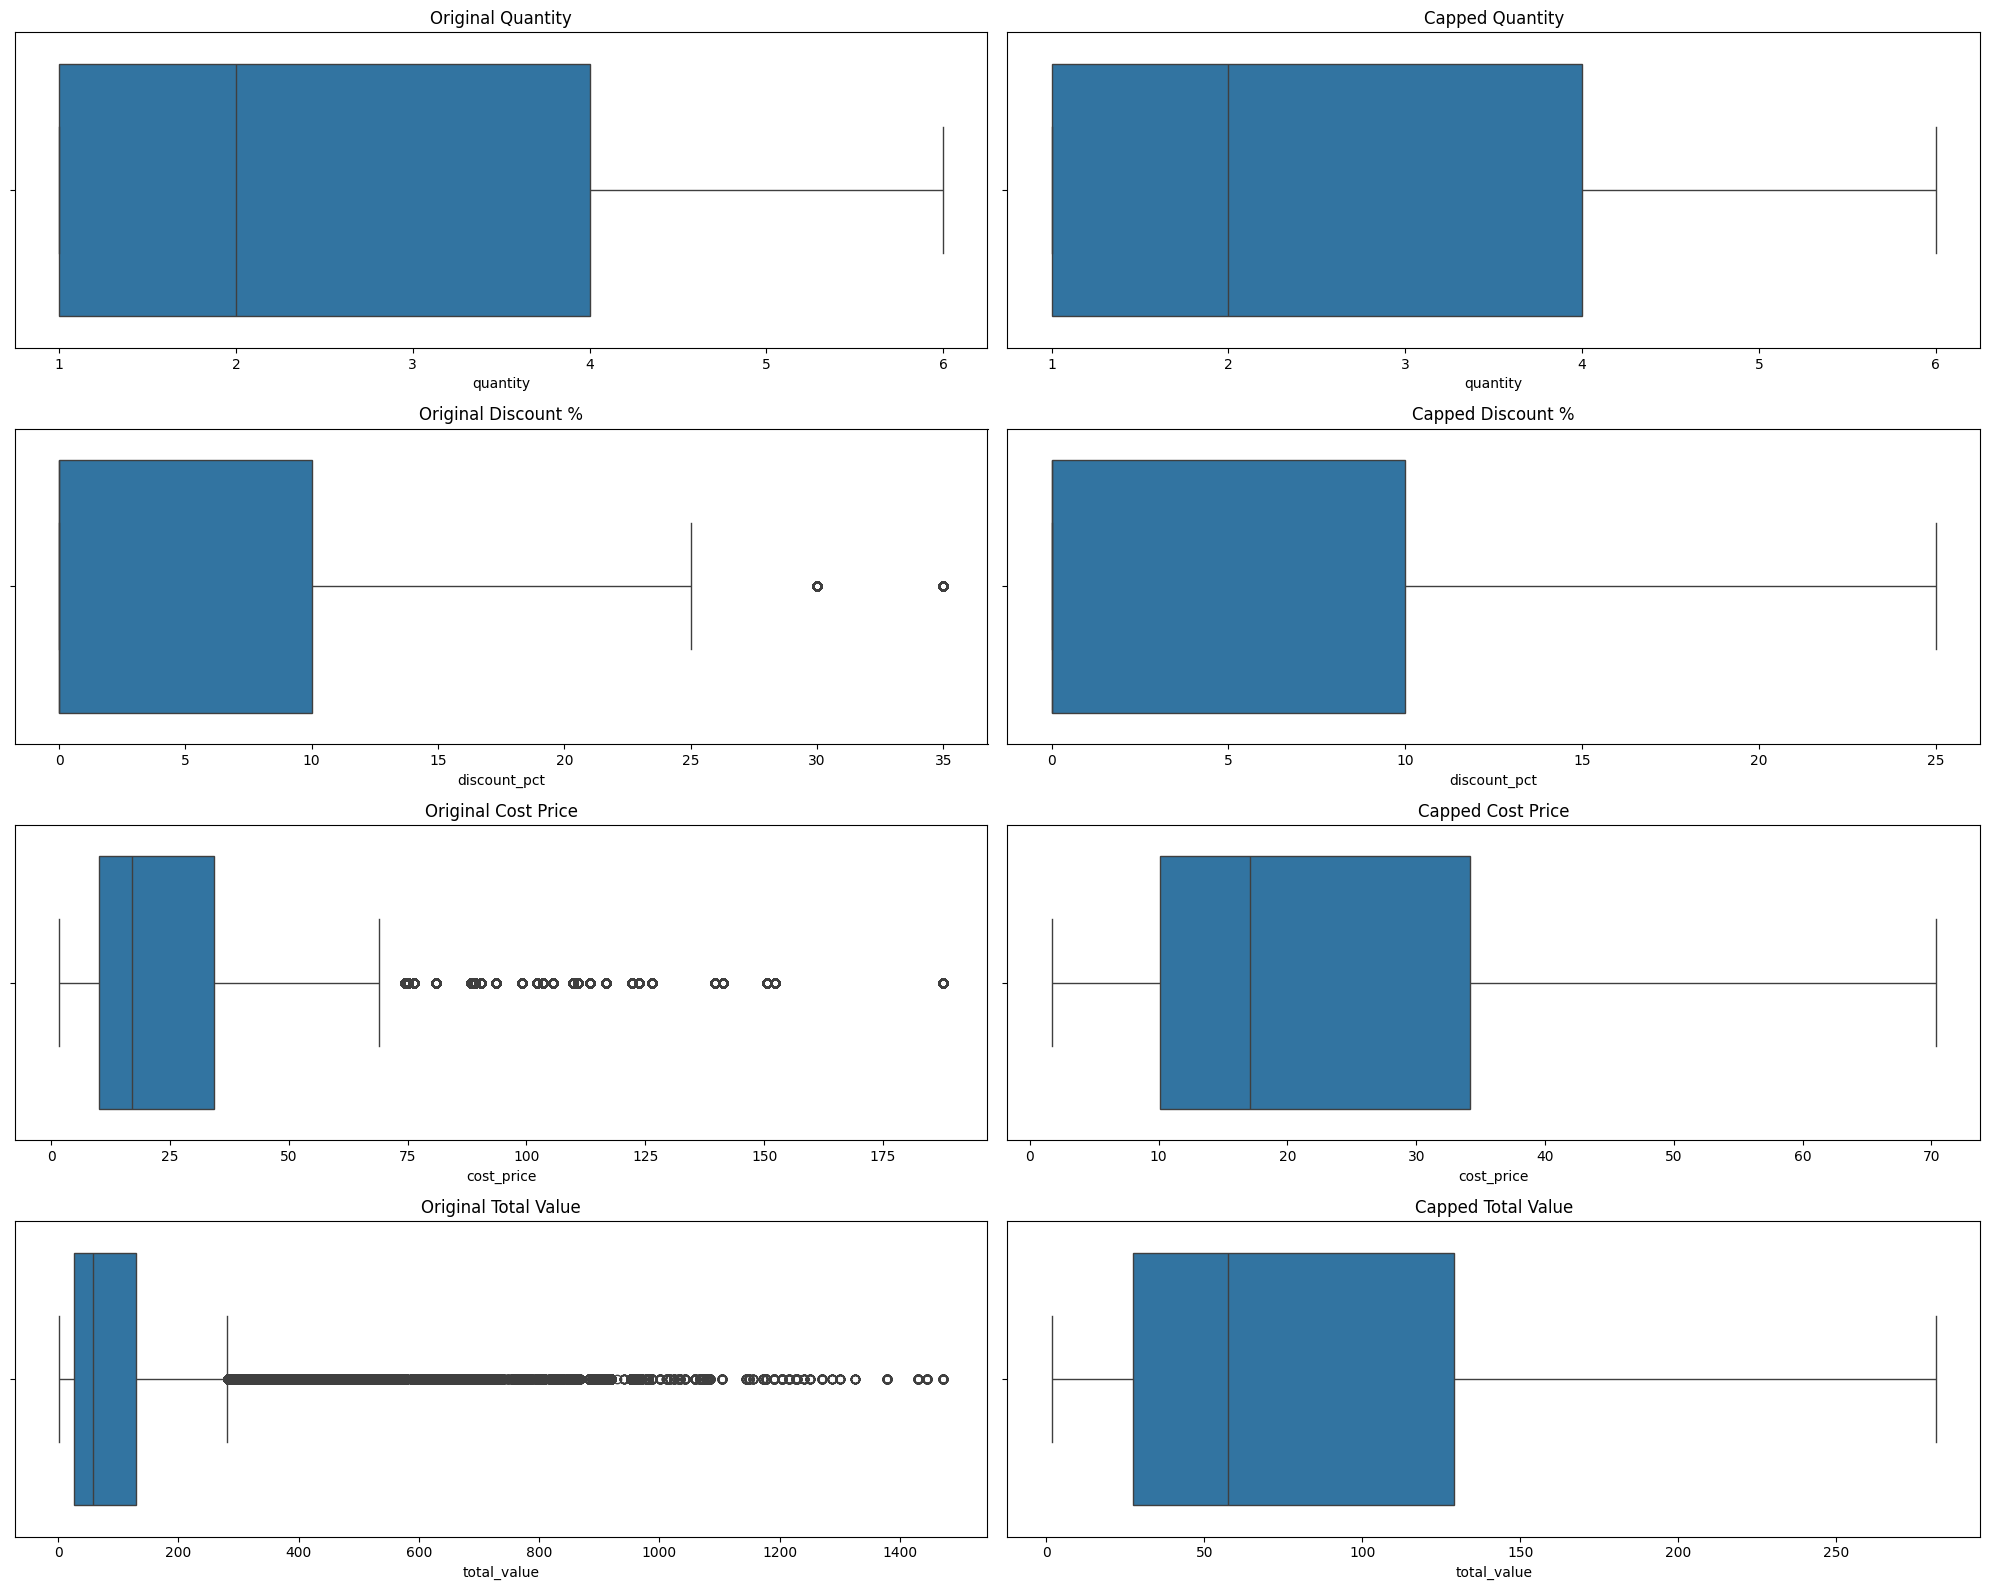

In [96]:
plt.figure(figsize=(20, 16))

# quantity comparison
plt.subplot(4, 2, 1)
sns.boxplot(x=df['quantity'])
plt.title('Original Quantity')
plt.subplot(4, 2, 2)
sns.boxplot(x=new_df['quantity'])
plt.title('Capped Quantity')

# discount_pct comparison
plt.subplot(4, 2, 3)
sns.boxplot(x=df['discount_pct'])
plt.title('Original Discount %')
plt.subplot(4, 2, 4)
sns.boxplot(x=new_df['discount_pct'])
plt.title('Capped Discount %')

# cost_price comparison
plt.subplot(4, 2, 5)
sns.boxplot(x=df['cost_price'])
plt.title('Original Cost Price')
plt.subplot(4, 2, 6)
sns.boxplot(x=new_df['cost_price'])
plt.title('Capped Cost Price')

# total_value comparison
plt.subplot(4, 2, 7)
sns.boxplot(x=df['total_value'])
plt.title('Original Total Value')
plt.subplot(4, 2, 8)
sns.boxplot(x=new_df['total_value'])
plt.title('Capped Total Value')

plt.tight_layout()
plt.show()

___
## Scatter ploting
___

In [97]:
new_df.head()

,date,store_id,sku_id,customer_id,quantity,total_value,channel,discount_pct,store_name,city,store_type,opening_date,sku_name,category,subcategory,cost_price,brand,Year,Month
0,2021-01-01,26,1124,2961.0,1.0,20.08,Store,15.0,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,Dairy_Cheese_1124,Dairy,Cheese,13.620,Premium,2021,1
3,2021-01-01,3,1164,3694.0,6.0,281.52,Website,0.0,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,Electronics_Cables_1164,Electronics,Cables,70.345,BlueMart,2021,1
4,2021-01-01,2,1093,1252.0,1.0,7.98,Store,0.0,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,Snacks_Chips_1093,Snacks,Chips,5.290,BlueMart,2021,1
5,2021-01-01,25,1067,1286.0,1.0,42.13,MobileApp,15.0,BlueMart Store 25,Dubai,High Street,2017-05-23 10:32:11.707317074,Grocery_Cereals_1067,Grocery,Cereals,32.380,Premium,2021,1
7,2021-01-01,38,1008,3160.0,2.0,74.70,Store,15.0,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,Personal Care_Shampoo_1008,Personal Care,Shampoo,31.770,Premium,2021,1


---

## Univariate Analysis
---

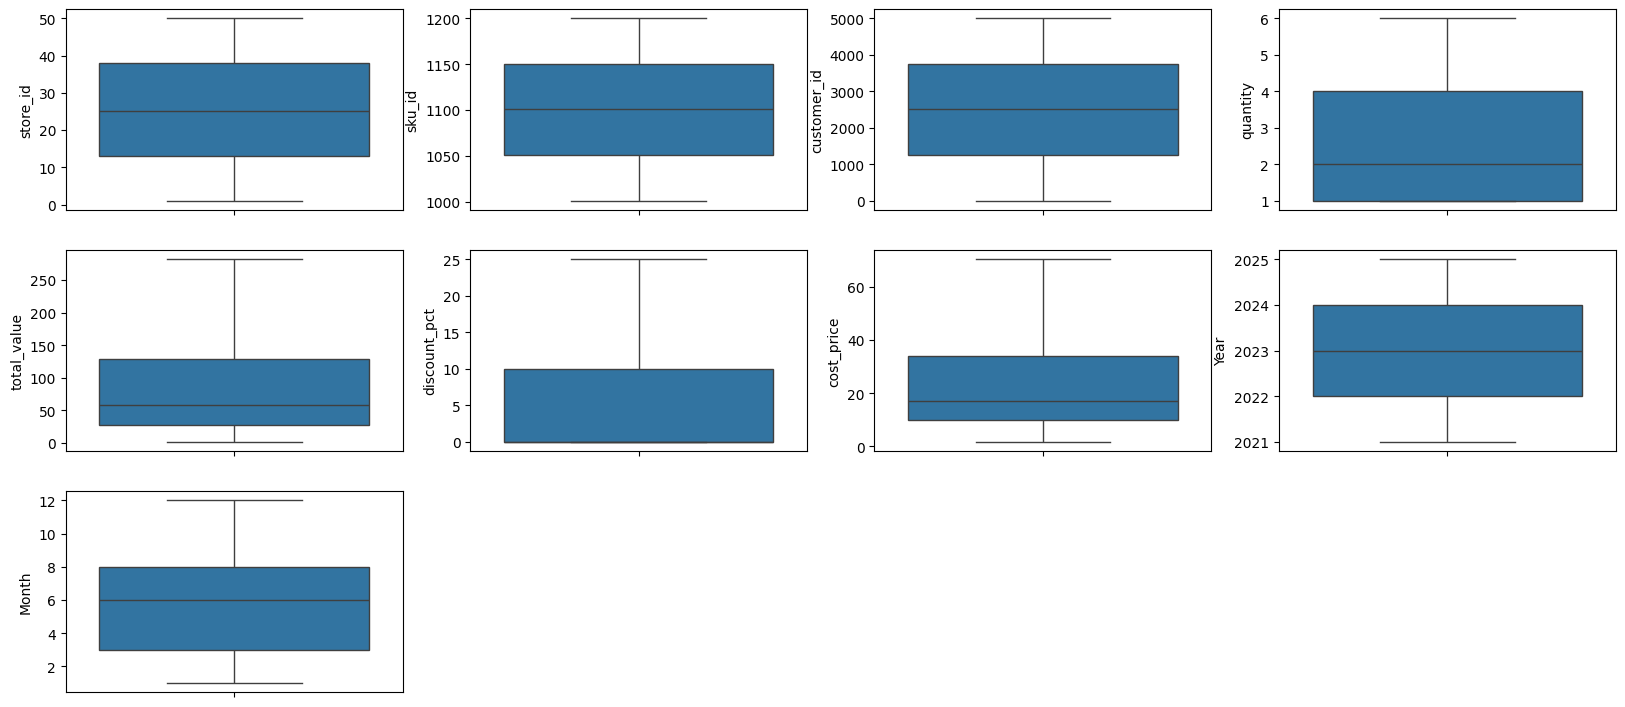

In [98]:
plt.figure(figsize=(20, 12))
for i, column in enumerate(new_df.select_dtypes(include='number'),1):
    plt.subplot(4,4,i)
    sns.boxplot(new_df[column])

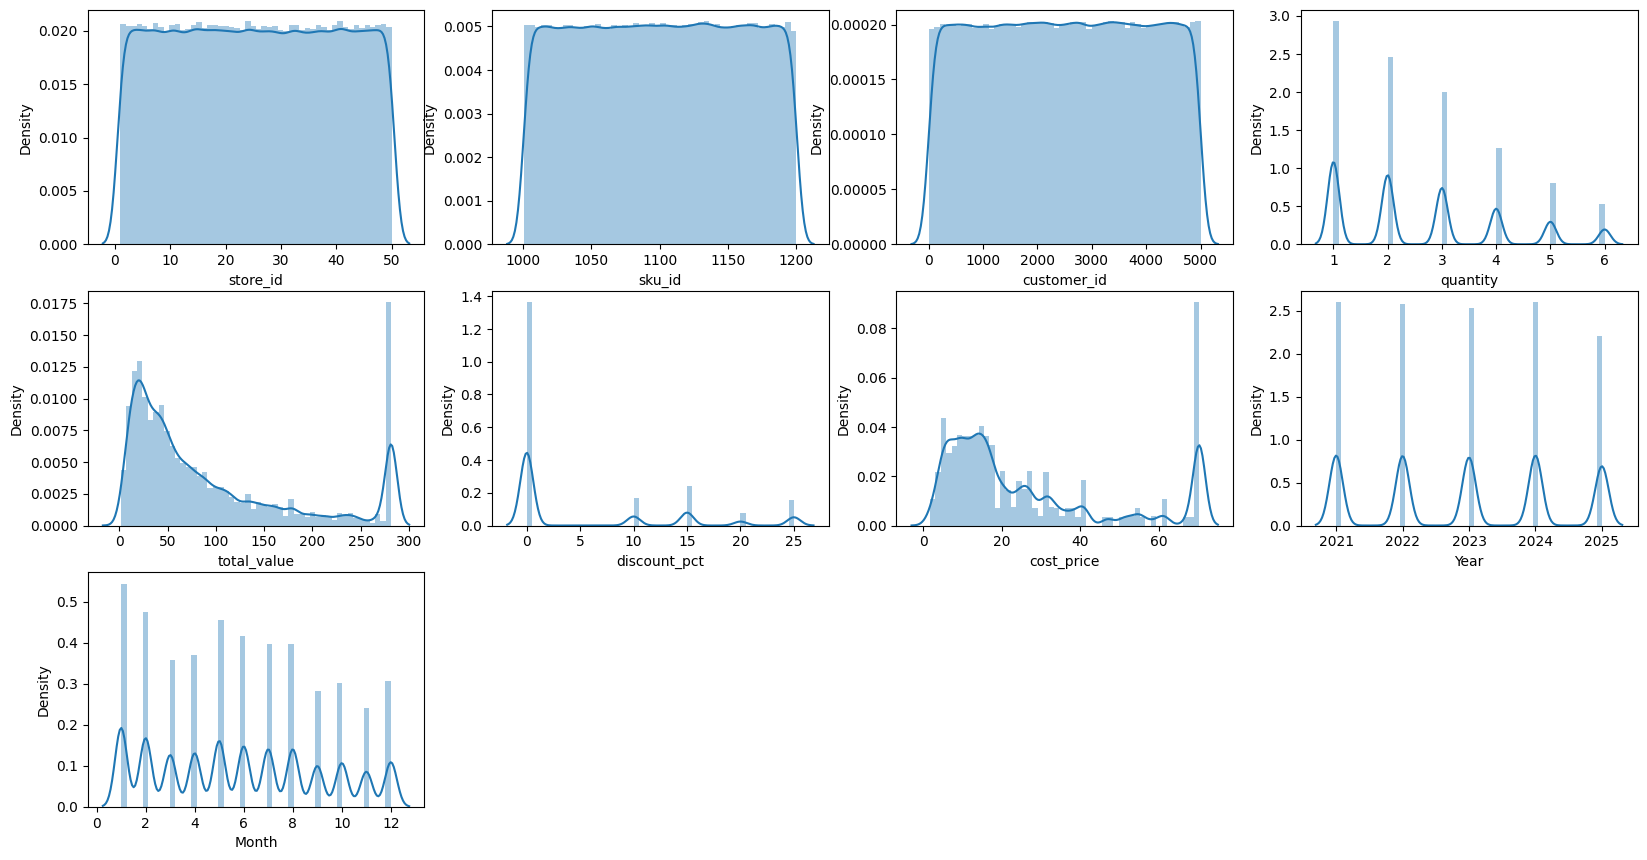

In [99]:
plt.figure(figsize=(20, 14))
for i, column in enumerate(new_df.select_dtypes(include='number'),1):
    plt.subplot(4,4,i)
    sns.distplot(new_df[column])

In [100]:
for i in new_df.select_dtypes(include='number'):
    skewness=new_df[i].skew()
    print("The skewness of",i,"is",skewness)

The skewness of store_id is 0.0012221261151560843
The skewness of sku_id is -0.0034633582094672592
The skewness of customer_id is -0.0027468656559125606
The skewness of quantity is 0.6798645050232596
The skewness of total_value is 1.166512236179331
The skewness of discount_pct is 1.2256446181256446
The skewness of cost_price is 1.0778183234337653
The skewness of Year is 0.04063817723709885
The skewness of Month is 0.20142963888786872
